In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt 

from tqdm import tqdm
from model import ExponentialRepresentation
from scipy.stats import binned_statistic_2d

In [2]:
def plot_ratemaps(x, y, f, n = 5, bins = 32, figsize = (2,2)):
    fig, ax = plt.subplots(n, n, figsize = figsize)
    axs = ax.ravel()
    hists = binned_statistic_2d(x,y, f.T, bins = bins)[0]

    for i in range(n**2):
        axs[i].imshow(hists[i])
        axs[i].axis("off")
    return hists

rectify = lambda x: np.maximum(x, np.mean(x))

In [3]:
A = torch.load("A.pt") # Must run optimize_constraints.ipynb first now!
B = torch.load("B.pt")

n_units = A.shape[0] # A.shape = B.shape, so
model = ExponentialRepresentation(A, B)

/var/folders/rv/mky69fln76nbwl7qkb06318h0000gn/T/ipykernel_55927/2674984441.py:1: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  A = torch.load("A.pt") # Must run optimize_co

In [4]:
f0 = torch.ones(n_units, dtype=torch.float32)/torch.sqrt(torch.tensor(n_units)) # unit starting vectors

In [5]:
ns = 10000 # number of spatial samples
r = 10*torch.rand((ns, 2)).to(torch.float32) # size of "arena"
v = torch.diff(r, dim = 0) # "velocities"
f_ = model(v, f0) # run

# blargh
f_ = f_.detach().numpy()
r = r.detach().numpy()

100%|██████████| 9998/9998 [00:03<00:00, 2623.24it/s]


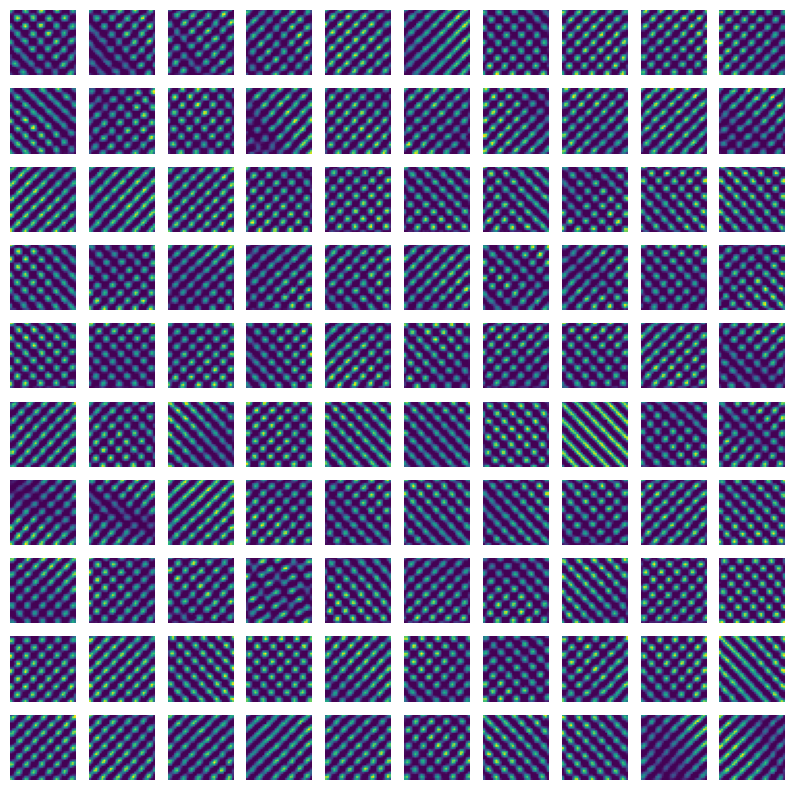

In [6]:
if rect:= True: # rectify or nay
    f = rectify(f_)
else:
    f = f_

ratemaps = plot_ratemaps(r[:-1,0], r[:-1,1], f, 10, figsize=(10,10), bins = 32)

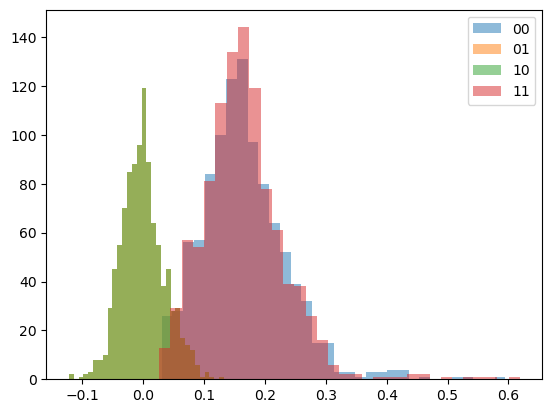

In [7]:
# estimate induced metric from ratemap Jacobian
fx, fy = np.gradient(ratemaps, axis=(-2, -1))

J = np.stack((fx.reshape(-1, 32*32), fy.reshape(-1, 32*32)), axis = -1)
J = J.transpose(1, 0 , 2) 
m = np.transpose(J, (0, 2, 1))@J # J^TJ

for i in range(2):
    for j in range(2):
        plt.hist(m[:,i,j], bins = 32, alpha = 0.5, label = f"{i}{j}")
plt.legend()

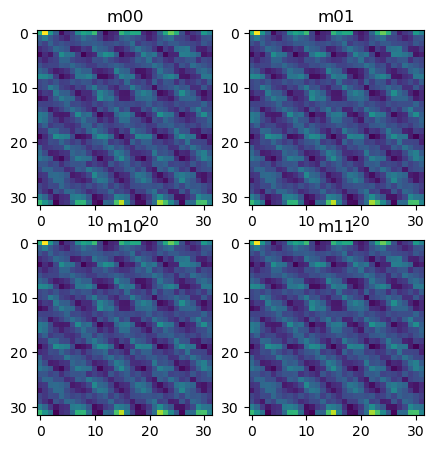

In [8]:
fig, ax = plt.subplots(2, 2, figsize = (5, 5))
ax[0,0].imshow(m[:,0,0].reshape(32,32))
ax[0,1].imshow(m[:,0,1].reshape(32,32))
ax[1,0].imshow(m[:,1,0].reshape(32,32))
ax[1,1].imshow(m[:,1,1].reshape(32,32))

for i in range(2):
    for j in range(2):
        ax[i, j].imshow(m[:,0,0].reshape(32,32))
        ax[i,j].set_title(f"m{i}{j}")

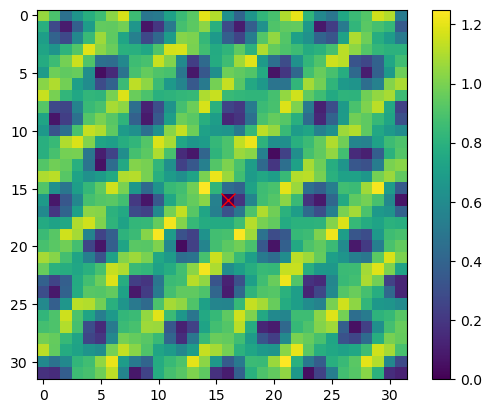

In [9]:
# plot squared distance from vector at [a,a] to all other pop. vecs.
a = 16
diff = (ratemaps[:,a,a,None,None] - ratemaps)**2
plt.imshow(np.sum(diff, axis = 0))
plt.plot(a,a, "rx", markersize = 10)
plt.colorbar()

In [10]:
def compute_centered_fourier(ratemaps):
    """
    Computes the centered Fourier transform of each image in the input array.

    Parameters:
    ratemaps (numpy.ndarray): Input array of shape (N, nx, ny) containing N images.

    Returns:
    numpy.ndarray: Centered Fourier transform of the input images, with shape (N, nx, ny).
    """
    return np.fft.fftshift(np.fft.fft2(ratemaps, axes=(-2, -1)), axes=(-2, -1))


In [11]:
fft = compute_centered_fourier(ratemaps)

In [12]:
max_indices = np.argmax(np.abs(fft).reshape(fft.shape[0], -1), axis=1)  # 1D index of max value for each fft[i]
max_coords = np.unravel_index(max_indices, fft.shape[1:])  # Convert to 2D (row, col) indices
rm = np.stack((max_coords[1], max_coords[0]), axis=-1)
rm.shape

(128, 2)

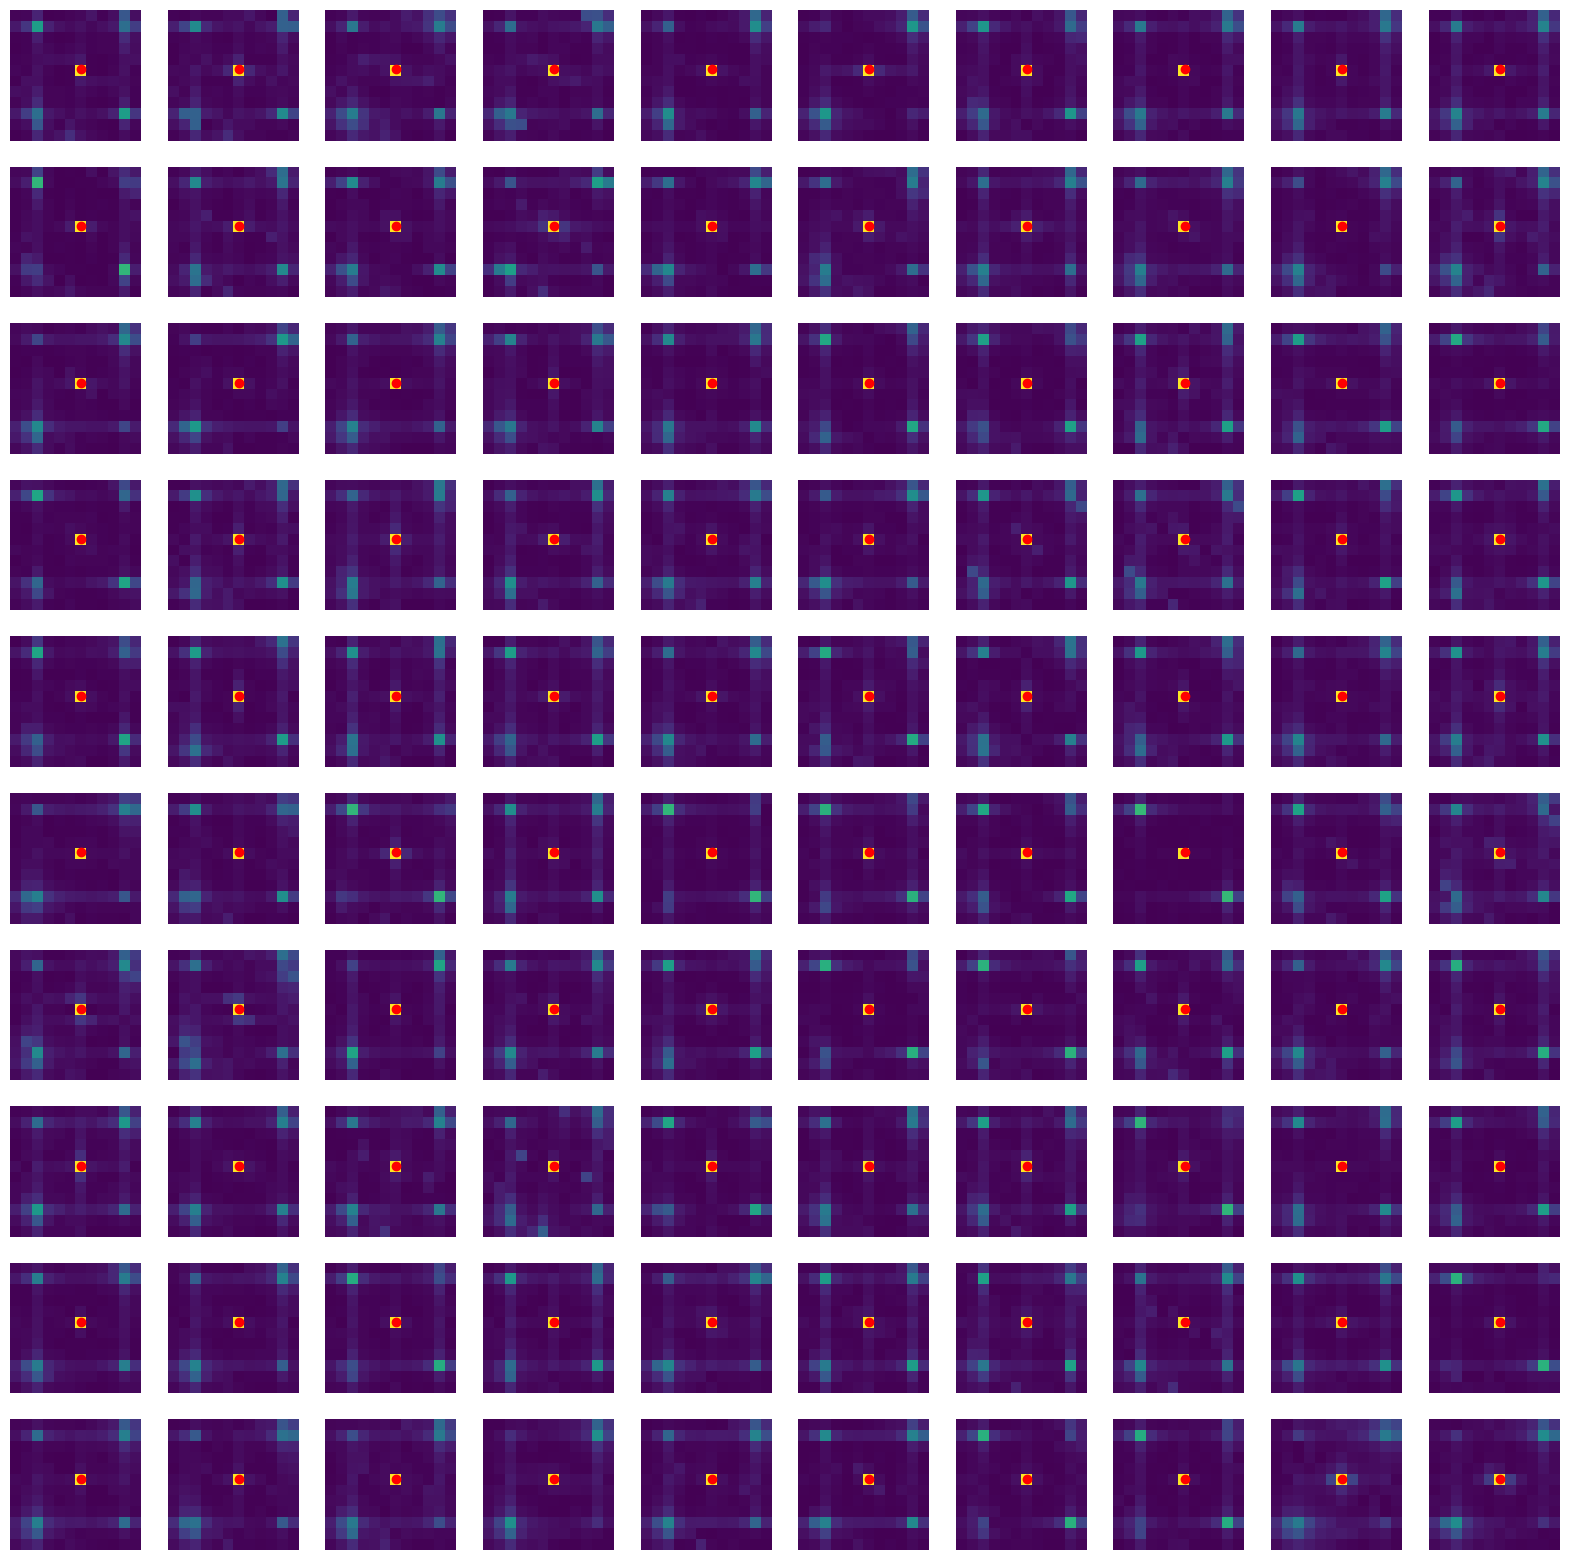

In [13]:
import numpy as np
import matplotlib.pyplot as plt

fig, axs = plt.subplots(10, 10, figsize=(20, 20))
axs = axs.ravel()

for i in range(100):
    axs[i].imshow(np.abs(fft[i])[10:-10, 10:-10], extent=(10, 21, 10, 21), origin = "lower")
    axs[i].axis("off")
    
    # Scatter at the correct (x, y) coordinate
    axs[i].scatter(rm[i,0], rm[i,1], c="r")
plt.show()


(array([  0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0., 128.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.]),
 array([4.21238898, 4.24363898, 4.27488898, 4.30613898, 4.33738898,
        4.36863898, 4.39988898, 4.43113898, 4.46238898, 4.49363898,
        4.52488898, 4.55613898, 4.58738898, 4.61863898, 4.64988898,
        4.68113898, 4.71238898, 4.74363898, 4.77488898, 4.80613898,
        4.83738898, 4.86863898, 4.89988898, 4.93113898, 4.96238898,
        4.99363898, 5.02488898, 5.05613898, 5.08738898, 5.11863898,
        5.14988898, 5.18113898, 5.21238898]),
 <BarContainer object of 32 artists>)

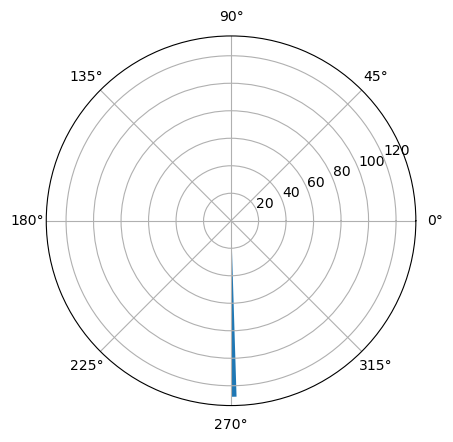

In [14]:
theta = np.arctan2(rm[:,1] - 16, rm[:,0] - 16) + np.pi*3/2
fig, ax = plt.subplots(subplot_kw=dict(polar=True))
plt.hist(theta, bins = 32)

In [15]:
(A@B - B@A).max()

tensor(5.5790e-05, dtype=torch.float32, grad_fn=<MaxBackward1>)